# Cattle Price — Exploratory Data Analysis

**Project:** ML Zoomcamp midterm. **Data:** SIO Carnes (MAGyP), January–June 2018.

**Scope:** steers and young steers (*novillos* and *novillitos*) from the Litoral provinces
(Entre Ríos, Santa Fe, Corrientes, Misiones) sold for slaughter per kg of live weight.

Questions:

1. How much will a lot be paid per kg of live weight?
2. Will a lot sell above the typical price of its category that week?
3. Which breeds are paid above the typical price?

Parts of this notebook (CRISP-DM):

1. Data understanding and cleaning (all cattle)
2. Scope, targets and univariate analysis
3. Bivariate analysis
4. Multivariate analysis
5. Conclusions and modelling dataset
6. Model training and selection (premium classification)

Every cleaning decision is written down with its reason, so the reviewer can follow (and challenge) it.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid")

DATA_RAW = Path("../data/raw")
DATA_PROCESSED = Path("../data/processed")
FIGURES = Path("../reports/figures")

## 1. Data understanding and cleaning

### 1.1 Load the raw data

The file published by MAGyP uses `;` as separator and `latin-1` encoding (reading it as UTF-8 fails
because of characters such as `ñ`).

In [2]:
raw = pd.read_csv(DATA_RAW / "sio-carnes-01-ene-a-30-jun-.csv", sep=";", encoding="latin-1")
print(f"Rows: {raw.shape[0]:,}  Columns: {raw.shape[1]}")
raw.head()

Rows: 544,858  Columns: 15


,pais_id,pais,provincia_origen_id,provincia_origen,departamento_origen_id,departamento_origen,zona_destino,fecha_comprobante,raza,categoria,cabezas_comercializadas,Unidad de Medida,precio($)_cabeza,precio($)_kg_vivo,cantidad_de_kg
0,32,Argentina,30,Entre Rios,56,Gualeguaychu,ZONA 2,2018-01-01,Aberdeen Angus,Bovino Novillitos Regulares,7,Kg. Vivo,NaN,20.00,"2,190.00"
1,32,Argentina,30,Entre Rios,56,Gualeguaychu,ZONA 2,2018-01-01,Aberdeen Angus,Bovino Vaquillona Regulares,11,Kg. Vivo,NaN,20.00,"3,300.00"
2,32,Argentina,6,Buenos Aires,175,Colon,ZONA 2,2018-01-01,Aberdeen Angus,Bovino Terneras hasta 350 kilos,7,Kg. Vivo,NaN,26.90,"2,426.00"
3,32,Argentina,6,Buenos Aires,175,Colon,ZONA 2,2018-01-01,Aberdeen Angus,Bovino Terneros hasta 350 kilos,7,Kg. Vivo,NaN,26.90,"2,429.00"
4,32,Argentina,6,Buenos Aires,651,Puan,ZONA 6,2018-01-01,Aberdeen Angus,Bovino Novillos Especiales y Buenos 461/490 kilos,10,Kg. Vivo,NaN,29.06,"4,811.00"


### 1.2 Data dictionary

Column names are translated to English `snake_case` to make the code easier to read.

| Original column | New name | Meaning |
|---|---|---|
| `pais_id`, `pais` | — | Country (always Argentina) → dropped |
| `provincia_origen_id`, `provincia_origen` | `origin_province` | Province where the lot comes from |
| `departamento_origen_id`, `departamento_origen` | `origin_department` | Department (county) where the lot comes from |
| `zona_destino` | `dest_zone` | Zone of the slaughterhouse (1–10, see README) |
| `fecha_comprobante` | `date` | Date of the sale |
| `raza` | `breed` | Breed declared in the tax settlement |
| `categoria` | `category` | Species + animal category (steer, heifer, cow…) |
| `cabezas_comercializadas` | `head` | Number of animals in the lot |
| `Unidad de Medida` | `unit` | How the price is expressed: per head, per kg live weight or per kg carcass |
| `precio($)_cabeza` | `price_head` | Price per head (ARS) |
| `precio($)_kg_vivo` | `price_kg` | Price per kg (ARS) |
| `cantidad_de_kg` | `total_kg` | Total kg of the lot |

In [3]:
RENAME = {
    "provincia_origen": "origin_province",
    "departamento_origen": "origin_department",
    "zona_destino": "dest_zone",
    "fecha_comprobante": "date",
    "raza": "breed",
    "categoria": "category",
    "cabezas_comercializadas": "head",
    "Unidad de Medida": "unit",
    "precio($)_cabeza": "price_head",
    "precio($)_kg_vivo": "price_kg",
    "cantidad_de_kg": "total_kg",
}

df = raw[list(RENAME)].rename(columns=RENAME)
df["date"] = pd.to_datetime(df["date"])
df.dtypes

origin_province                 str
origin_department               str
dest_zone                       str
date                 datetime64[us]
breed                           str
category                        str
head                          int64
unit                            str
price_head                  float64
price_kg                    float64
total_kg                    float64
dtype: object

### 1.3 Missing values

In [4]:
df.isna().mean().sort_values(ascending=False).to_frame("share_missing")

,share_missing
price_head,0.93
price_kg,0.07
total_kg,0.07
dest_zone,0.00
origin_department,0.00
origin_province,0.00
date,0.00
head,0.00
category,0.00
breed,0.00


In [5]:
# Are the missing prices related to the unit of measure?
pd.crosstab(df["unit"], [df["price_head"].isna(), df["price_kg"].isna()],
            rownames=["unit"], colnames=["price_head missing", "price_kg missing"])

price_head missing,False,True
price_kg missing,True,False
unit,,
Cabeza,37759,0
Kg. Carne,0,7934
Kg. Vivo,484,498681


**Interpretation:** the missing values are **structural**, not errors. Lots priced per head (`Cabeza`)
have no `price_kg` or `total_kg`; lots priced per kg have no `price_head`.
Only a few hundred `Kg. Vivo` rows have both prices empty.

**Decision:** keep all units for the flow and breed questions (price is not needed there),
and use weight-based features only where `unit == "Kg. Vivo"`.

### 1.4 Species

The first word of `category` gives the species. SIO Carnes covers cattle (`Bovino`) and water buffalo (`Bubalino`).

In [6]:
df["species"] = df["category"].str.split().str[0]
df["species"].value_counts()

species
Bovino      537553
Bubalino      7305
Name: count, dtype: int64

**Decision:** keep only `Bovino`. Buffalo are a different production system and a small share of the data.

### 1.5 Exact duplicate rows

There is no transaction ID, so two identical rows could be (a) the same operation recorded twice, or
(b) two different lots that happen to share every value (same day, department, breed, category, head, price and kg).

In [7]:
n_dup = df.duplicated().sum()
print(f"Exact duplicate rows: {n_dup:,} ({n_dup / len(df):.1%})")

copies = df.groupby(list(df.columns), dropna=False).size()
copies.value_counts().sort_index().head(10).to_frame("groups with this many copies")

Exact duplicate rows: 129,807 (23.8%)


,groups with this many copies
1,336508
2,57159
3,9360
4,5909
5,2027
6,1811
7,499
8,656
9,289
10,357


**Interpretation:** almost a quarter of the rows are exact copies, and some rows appear 10 or more times.
Two different lots matching on *every* column, including price and total kg, is unlikely at this scale.

**Decision:** drop exact duplicates. Keeping them would inflate the weekly volumes (question C) and,
worse, the same row could land in both the training and the test set, making the metrics look better than they are.
This is an assumption; it is documented in the README.

### 1.6 Number of head per lot

In [8]:
df["head"].describe(percentiles=[0.5, 0.9, 0.99, 0.999, 0.9999])

count      544,858.00
mean            20.45
std          2,808.18
min             -1.00
50%              6.00
90%             33.00
99%             58.00
99.9%           99.00
99.99%       3,626.47
max      1,845,915.00
Name: head, dtype: float64

In [9]:
print(f"Lots with head <= 0: {(df['head'] <= 0).sum()}")
df.sort_values("head", ascending=False)[["origin_province", "category", "unit", "head", "total_kg"]].head(10)

Lots with head <= 0: 5


,origin_province,category,unit,head,total_kg
91504,Cordoba,Bovino Vaquillona Regulares,Kg. Vivo,1845915,"16,756.00"
544456,Santa Fe,Bovino Vaca Regulares,Kg. Vivo,827120,"3,200.00"
298354,Buenos Aires,Bovino Vaquillona Regulares,Kg. Vivo,213023,"2,535.00"
150579,Buenos Aires,Bovino Vaca Regulares,Kg. Vivo,213010,774.00
462123,Santa Fe,Bovino Vaquillona Regulares,Kg. Vivo,173024,"5,938.00"
336140,Santa Fe,Bovino Vaquillona Regulares,Kg. Vivo,173013,"1,212.00"
388994,Buenos Aires,Bovino Novillitos Especiales y Buenos Medianos...,Kg. Vivo,80112,"15,029.00"
103616,Buenos Aires,Bovino Novillos Especiales y Buenos 491/520 kilos,Kg. Vivo,80020,"18,030.00"
103619,Buenos Aires,Bovino Novillos Especiales y Buenos 491/520 kilos,Kg. Vivo,80020,"18,030.00"
479405,Buenos Aires,Bovino Novillitos Regulares,Kg. Vivo,71327,"2,669.00"


**Interpretation:** 99.9% of lots have fewer than 100 head, but there are lots with tens of thousands
(even 1.8 million) head — with only a few thousand kg in total. These are typing errors
(they look like other fields pasted into `head`).

The average weight per head (next section) catches most of these errors for `Kg. Vivo` lots.
For lots priced per head, there is no weight to check them against.

**Decision:** drop `head <= 0`, and drop lots with more than **1,000 head** (more than 10 times the 99.9th percentile).

### 1.7 Average weight per head

For lots sold per kg live weight, `avg_weight = total_kg / head` must be a realistic animal weight.
Calves are around 150–350 kg, cows and steers 350–550 kg, bulls up to about 1,000 kg.

In [10]:
kg_live = df[(df["unit"] == "Kg. Vivo") & (df["head"] > 0)].copy()
kg_live["avg_weight"] = kg_live["total_kg"] / kg_live["head"]
kg_live["avg_weight"].describe(percentiles=[0.001, 0.01, 0.5, 0.99, 0.999])

count   498,680.00
mean        427.53
std         117.23
min           0.00
0.1%        115.45
1%          277.53
50%         403.33
99%         770.00
99.9%       940.00
max      11,620.00
Name: avg_weight, dtype: float64

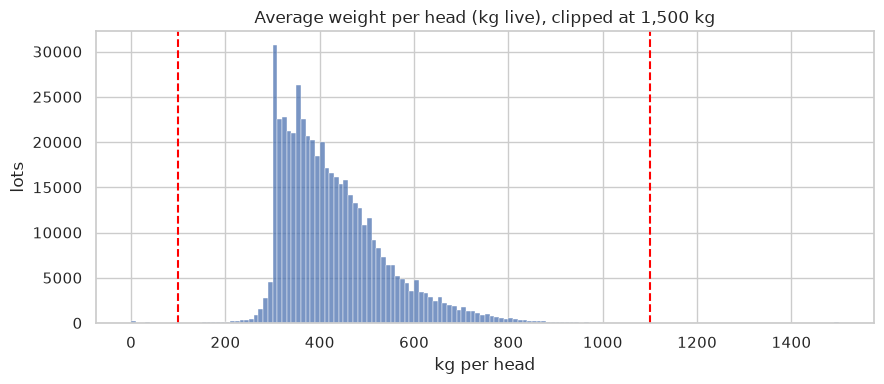

Lots outside 100-1100 kg/head: 1,044 (0.21%)


In [11]:
MIN_WEIGHT, MAX_WEIGHT = 100, 1100

fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(kg_live["avg_weight"].clip(upper=1500), bins=150, ax=ax)
for limit in (MIN_WEIGHT, MAX_WEIGHT):
    ax.axvline(limit, color="red", linestyle="--")
ax.set(title="Average weight per head (kg live), clipped at 1,500 kg",
       xlabel="kg per head", ylabel="lots")
plt.tight_layout()
plt.savefig(FIGURES / "01_avg_weight_per_head.png", dpi=120)
plt.show()

outside = ~kg_live["avg_weight"].between(MIN_WEIGHT, MAX_WEIGHT)
print(f"Lots outside {MIN_WEIGHT}-{MAX_WEIGHT} kg/head: {outside.sum():,} ({outside.mean():.2%})")

**Decision:** for `Kg. Vivo` lots, keep only an average weight between **100 and 1,100 kg per head**.
This removes impossible values (0 kg lots, 11,000 kg "animals") and very few real lots.

### 1.8 Dates

In [12]:
print("From", df["date"].min().date(), "to", df["date"].max().date())
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
df["date"].dt.day_of_week.map(dict(enumerate(days))).value_counts().reindex(days).to_frame("lots")

From 2018-01-01 to 2018-06-30


,lots
date,
Mon,79571
Tue,129345
Wed,126203
Thu,87229
Fri,81566
Sat,25553
Sun,15391


**Interpretation:** the data covers 26 weeks. Most sales happen Monday–Friday, which matters for question C:
volumes should be aggregated **by week**, not by day, to avoid the weekday effect.

### 1.9 "Ciudad Autónoma de Buenos Aires" as an origin

The City of Buenos Aires has no farms, yet it appears as an origin. Let's compare it with the rest.

In [13]:
is_caba = df["origin_province"] == "Ciudad Autonoma De Buenos Aires"
print(f"Lots from CABA: {is_caba.sum():,} ({is_caba.mean():.1%})")
print("Departments:", df.loc[is_caba, "origin_department"].unique())

pd.DataFrame({
    "CABA": df.loc[is_caba, "breed"].value_counts(normalize=True),
    "Rest": df.loc[~is_caba, "breed"].value_counts(normalize=True),
}).fillna(0).sort_values("CABA", ascending=False).head(8)

Lots from CABA: 74,341 (13.6%)
Departments: <StringArray>
['Ciudad Autonoma De Buenos Aires']
Length: 1, dtype: str


,CABA,Rest
breed,,
Bovino Criollo,0.64,0.27
Otra 99,0.27,0.19
Aberdeen Angus,0.09,0.32
Limangus,0.00,0.00
Hereford,0.00,0.06
Holando Argentino,0.00,0.07
Brahman,0.00,0.00
Braford,0.00,0.06


**Interpretation:** CABA has a single department and only a handful of breeds, very different from real farming areas.
The most likely explanation is a **livestock market** located in the city (an intermediary), not the farm of origin.
This is a hypothesis: the dataset documentation does not say it.

**Decision:** keep CABA in the cleaned data with a flag `is_market_origin`, and decide per question:
it is excluded from question B (breed) and C (volume per department), where "origin" must mean the farm.

### 1.10 Origin zone

The official zone table maps each origin to one of the 10 zones. Outside Buenos Aires province the zone
depends only on the province; inside Buenos Aires it depends on the department.
A few department names are written differently in the two files, so they are fixed with an explicit table.

In [14]:
zones = pd.read_csv(DATA_RAW / "zonas-sio-carnes-.csv")
zones["zona"] = zones["zona"].str.strip().str.upper()
zones["departamento"] = zones["departamento"].replace({"Caã‘Uelas": "Cañuelas"})  # encoding error in the source file

by_province = (zones[zones["departamento"] == "Todos Los Departamentos"]
               .set_index("provincia")["zona"].to_dict())
by_department = (zones[zones["departamento"] != "Todos Los Departamentos"]
                 .set_index(["provincia", "departamento"])["zona"].to_dict())

# Department names in the operations file -> names in the zones file
DEPARTMENT_FIXES = {
    "9 De Julio": "Nueve De Julio",
    "25 De Mayo": "Veinticinco De Mayo",
    "Leandro N Alem": "Leandro N. Alem",
    "General Juan Madariaga": "General Madariaga",
    "General La Madrid": "General Lamadrid",
    "Adolfo Gonzales Chaves": "Gonzales Chaves",
    "Brandsen": "Coronel Brandsen",
    "Florentino Ameghino": "Ameghino",
    "Coronel de Marina L Rosales": "Coronel Rosales",
}


def origin_zone(province, department):
    if province in by_province:
        return by_province[province]
    department = DEPARTMENT_FIXES.get(department, department)
    return by_department.get((province, department))


pairs = df[["origin_province", "origin_department"]].drop_duplicates()
pairs["origin_zone"] = [origin_zone(p, d) for p, d in zip(pairs["origin_province"], pairs["origin_department"])]
print("Origins without a zone:", pairs["origin_zone"].isna().sum())
pairs[pairs["origin_zone"].isna()]

Origins without a zone: 0


,origin_province,origin_department,origin_zone


### 1.11 Cleaning pipeline

All the decisions above, applied in order in one function. The table shows how many rows each step removes.

In [15]:
def clean(data: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    log = [("raw", len(data))]

    data = data.drop_duplicates()
    log.append(("drop exact duplicates", len(data)))

    data = data[data["species"] == "Bovino"]
    log.append(("keep cattle (Bovino)", len(data)))

    data = data[data["head"].between(1, 1000)]
    log.append(("1 <= head <= 1000", len(data)))

    data = data.assign(avg_weight=np.where(data["unit"] == "Kg. Vivo", data["total_kg"] / data["head"], np.nan))
    bad_weight = (data["unit"] == "Kg. Vivo") & ~data["avg_weight"].between(MIN_WEIGHT, MAX_WEIGHT)
    data = data[~bad_weight]
    log.append((f"kg live: {MIN_WEIGHT}-{MAX_WEIGHT} kg/head", len(data)))

    data = data.merge(pairs, on=["origin_province", "origin_department"], how="left")
    data = data.assign(
        dest_zone=data["dest_zone"].str.upper(),
        is_market_origin=data["origin_province"].eq("Ciudad Autonoma De Buenos Aires"),
    )

    steps = pd.DataFrame(log, columns=["step", "rows"])
    steps["removed"] = -steps["rows"].diff().fillna(0).astype(int)
    return data.reset_index(drop=True), steps


clean_df, steps = clean(df)
steps

,step,rows,removed
0,raw,544858,0
1,drop exact duplicates,415051,129807
2,keep cattle (Bovino),410358,4693
3,1 <= head <= 1000,410301,57
4,kg live: 100-1100 kg/head,409697,604


In [16]:
print(f"Rows kept: {len(clean_df):,} of {len(df):,} ({len(clean_df) / len(df):.1%})")
print("Rows without origin zone:", clean_df["origin_zone"].isna().sum())
clean_df.head()

Rows kept: 409,697 of 544,858 (75.2%)
Rows without origin zone: 0


,origin_province,origin_department,dest_zone,date,breed,category,head,unit,price_head,price_kg,total_kg,species,avg_weight,origin_zone,is_market_origin
0,Entre Rios,Gualeguaychu,ZONA 2,2018-01-01,Aberdeen Angus,Bovino Novillitos Regulares,7,Kg. Vivo,NaN,20.00,"2,190.00",Bovino,312.86,ZONA 5,False
1,Entre Rios,Gualeguaychu,ZONA 2,2018-01-01,Aberdeen Angus,Bovino Vaquillona Regulares,11,Kg. Vivo,NaN,20.00,"3,300.00",Bovino,300.00,ZONA 5,False
2,Buenos Aires,Colon,ZONA 2,2018-01-01,Aberdeen Angus,Bovino Terneras hasta 350 kilos,7,Kg. Vivo,NaN,26.90,"2,426.00",Bovino,346.57,ZONA 2,False
3,Buenos Aires,Colon,ZONA 2,2018-01-01,Aberdeen Angus,Bovino Terneros hasta 350 kilos,7,Kg. Vivo,NaN,26.90,"2,429.00",Bovino,347.00,ZONA 2,False
4,Buenos Aires,Puan,ZONA 6,2018-01-01,Aberdeen Angus,Bovino Novillos Especiales y Buenos 461/490 kilos,10,Kg. Vivo,NaN,29.06,"4,811.00",Bovino,481.10,ZONA 4,False


### 1.12 Save the cleaned data

In [17]:
DATA_PROCESSED.mkdir(parents=True, exist_ok=True)
clean_df.to_csv(DATA_PROCESSED / "sio_carnes_clean.csv.gz", index=False)
print("Saved", DATA_PROCESSED / "sio_carnes_clean.csv.gz")

Saved ../data/processed/sio_carnes_clean.csv.gz


### Summary of Part 1

| Topic | Finding | Decision |
|---|---|---|
| Encoding | File is `latin-1`, separator `;` | Read with those options |
| Missing prices | Structural: depend on the unit of measure | Keep; weight features only for `Kg. Vivo` |
| Species | Small share of buffalo | Keep only cattle |
| Duplicates | ~24% exact copies | Drop them (assumption, documented) |
| Head per lot | Impossible values (up to 1.8 M head) | Keep 1–1,000 head |
| Weight per head | Impossible values (0 kg, >11,000 kg) | Keep 100–1,100 kg/head for `Kg. Vivo` |
| Dates | Sales concentrated Mon–Fri | Aggregate volume by week |
| CABA origin | Looks like a market, not farms | Flag it; exclude from B and C |
| Origin zone | 10 department names written differently | Fixed with an explicit table; every origin now has a zone |

**Next:** Part 2 narrows the data to the project scope.

---
## 2. Scope, targets and univariate analysis

*Course reference: C2 (summary statistics), C3 (charts), C4 (normality).*

### 2.1 Scope of the project

The project focuses on:

- **Categories:** steers (*novillos*) and young steers (*novillitos*), the main categories of the use case.
- **Origin:** the Litoral provinces **Entre Ríos, Santa Fe, Corrientes and Misiones**.
- **Unit:** lots priced per kg of live weight (the only ones with a price per kg).

### 2.2 Target variables

- `typical_price`: median price of the **same category in the same week**, computed with the steer lots of the **whole country**.
  It is the market reference; using all provinces makes it stable (few lots per week would make a regional median noisy).
- `rel_price` = `price_kg / typical_price`. A value of 1.05 means "5% above the national typical price".
- `premium` = 1 if `rel_price > 1`, else 0.

Comparing each lot with its own category and week removes inflation (prices rose during 2018) and the price differences between categories.

In [18]:
from scipy import stats

PROVINCES = ["Entre Rios", "Santa Fe", "Corrientes", "Misiones"]
GROUPS = ["Novillos", "Novillitos"]

kg_live = clean_df[(clean_df["unit"] == "Kg. Vivo") & clean_df["price_kg"].notna()].copy()
kg_live["group"] = kg_live["category"].str.split().str[1]
kg_live["week"] = kg_live["date"].dt.isocalendar().week.astype(int)
kg_live["weekday"] = kg_live["date"].dt.day_name()

# Reference market: steers and young steers of the whole country
steers = kg_live[kg_live["group"].isin(GROUPS)].copy()
reference = steers.groupby(["category", "week"])["price_kg"]
steers["typical_price"] = reference.transform("median")
steers["reference_lots"] = reference.transform("size")
steers["rel_price"] = steers["price_kg"] / steers["typical_price"]
steers["premium"] = (steers["rel_price"] > 1).astype(int)

# Project scope: Litoral
lots = steers[steers["origin_province"].isin(PROVINCES)].copy()
lots["log_head"] = np.log(lots["head"])
lots["log_weight"] = np.log(lots["avg_weight"])

scope = pd.DataFrame({
    "lots": [len(kg_live), len(steers), len(lots), (lots["origin_province"] == "Entre Rios").sum()],
}, index=["all cattle, kg live", "steers, whole country (reference)", "steers, Litoral (project scope)", "of which Entre Ríos"])
print(f"Lots whose typical price comes from fewer than 30 reference lots: {(lots['reference_lots'] < 30).mean():.1%}")
scope

Lots whose typical price comes from fewer than 30 reference lots: 3.6%


,lots
"all cattle, kg live",375861
"steers, whole country (reference)",114703
"steers, Litoral (project scope)",24466
of which Entre Ríos,9496


In [19]:
lots.groupby(["origin_province", "group"]).size().unstack()

group,Novillitos,Novillos
origin_province,,
Corrientes,302,636
Entre Rios,5535,3961
Misiones,122,81
Santa Fe,7938,5891


**Interpretation**

- The scope keeps about 24,500 lots. **Santa Fe and Entre Ríos are 95%** of them; Corrientes and Misiones add few lots.
- Only 3.6% of the lots have a typical price based on fewer than 30 national lots, so the reference is stable.

### 2.3 Summary statistics (C2)

Position (mean, median), dispersion (standard deviation, coefficient of variation, IQR) and shape (skewness, kurtosis).

In [20]:
NUMERIC = ["price_kg", "rel_price", "avg_weight", "head", "total_kg"]


def summarize(data, columns):
    rows = {}
    for col in columns:
        x = data[col]
        rows[col] = {
            "mean": x.mean(), "median": x.median(), "std": x.std(),
            "cv": x.std() / x.mean(),
            "q1": x.quantile(0.25), "q3": x.quantile(0.75), "iqr": x.quantile(0.75) - x.quantile(0.25),
            "min": x.min(), "max": x.max(),
            "skewness": stats.skew(x), "kurtosis": stats.kurtosis(x),   # 0 = normal curve
        }
    return pd.DataFrame(rows).T


summarize(lots, NUMERIC)

,mean,median,std,cv,q1,q3,iqr,min,max,skewness,kurtosis
price_kg,29.95,30.00,5.42,0.18,26.98,34.00,7.02,8.00,49.90,-0.52,0.67
rel_price,0.98,0.99,0.16,0.17,0.88,1.09,0.22,0.26,1.80,-0.57,0.77
avg_weight,418.91,400.00,85.85,0.20,357.14,469.65,112.51,111.11,"1,050.00",1.03,1.57
head,11.71,6.00,13.32,1.14,2.00,16.00,14.00,1.00,206.00,2.12,8.86
total_kg,"5,038.43","2,460.00","6,117.96",1.21,962.25,"6,284.75","5,322.50",150.00,"94,000.00",2.36,11.72


**Interpretation**

- `price_kg`: mean and median are both about 30 ARS/kg with a low coefficient of variation (0.18). Steers are a much more
  homogeneous group than all cattle together.
- `rel_price`: the median is 0.99 and the mean 0.98: Litoral steers are paid **slightly below** the national typical price.
  Negative skew (-0.6): there are more lots sold far below the reference than far above it.
- `avg_weight`: around 400 kg, moderate positive skew.
- `head` and `total_kg`: strong positive skew and a coefficient of variation above 1 (half of the lots have 6 animals or fewer, a few have more than 100).
  **Median and IQR** describe them better than mean and standard deviation (C2).

### 2.4 Distributions: histograms and boxplots (C3)

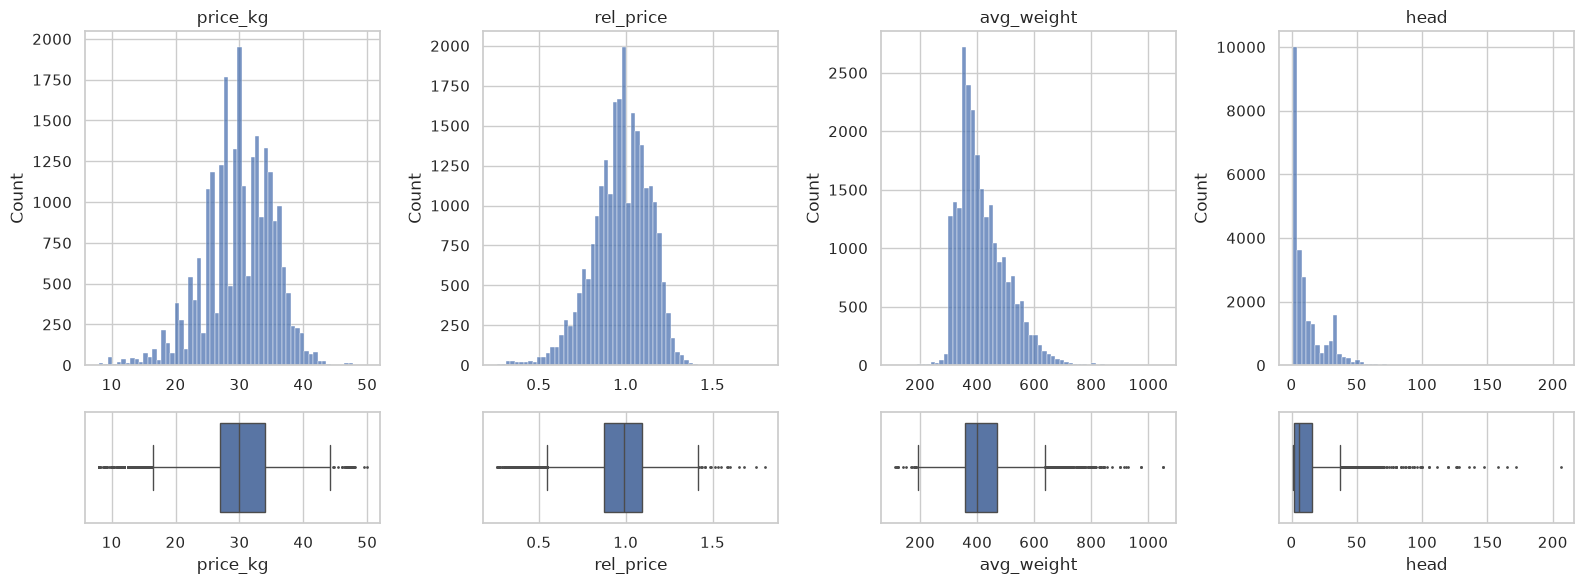

In [21]:
fig, axes = plt.subplots(2, 4, figsize=(16, 6), gridspec_kw={"height_ratios": [3, 1]})
for i, col in enumerate(["price_kg", "rel_price", "avg_weight", "head"]):
    sns.histplot(lots[col], bins=60, ax=axes[0, i])
    sns.boxplot(x=lots[col], ax=axes[1, i], fliersize=1)
    axes[0, i].set(title=col, xlabel="")
plt.tight_layout()
plt.savefig(FIGURES / "02_univariate_distributions.png", dpi=120)
plt.show()

**Interpretation**

- `price_kg` has one main peak near 30 ARS/kg and a tail to the left. Spikes at round numbers (25, 28, 30) show that prices are negotiated.
- `rel_price` is concentrated between 0.9 and 1.1, with a longer left tail.
- `avg_weight` shows the weight ranges of the categories; `head` is strongly right-skewed.

### 2.5 Normality (C4)

C4 presents **Shapiro-Wilk**, recommended for small samples (up to about 50 observations), and
**Kolmogorov-Smirnov with the Lilliefors correction** for larger ones. With thousands of rows any test rejects normality
for tiny deviations, so the tests are run on random samples and read together with the **Q-Q plot**.

In [22]:
from statsmodels.stats.diagnostic import lilliefors

NORMALITY_VARS = ["price_kg", "rel_price", "avg_weight", "log_weight", "head", "log_head"]
rng = np.random.default_rng(42)
rows = []
for col in NORMALITY_VARS:
    values = lots[col].to_numpy()
    rows.append({
        "variable": col,
        "skewness": stats.skew(values),
        "Shapiro-Wilk p (n=50)": stats.shapiro(rng.choice(values, 50, replace=False)).pvalue,
        "Lilliefors p (n=5000)": lilliefors(rng.choice(values, 5000, replace=False))[1],
    })
pd.DataFrame(rows).set_index("variable").round(3)

,skewness,Shapiro-Wilk p (n=50),Lilliefors p (n=5000)
variable,,,
price_kg,-0.52,0.00,0.00
rel_price,-0.57,0.03,0.00
avg_weight,1.03,0.00,0.00
log_weight,0.38,0.70,0.00
head,2.12,0.00,0.00
log_head,0.01,0.01,0.00


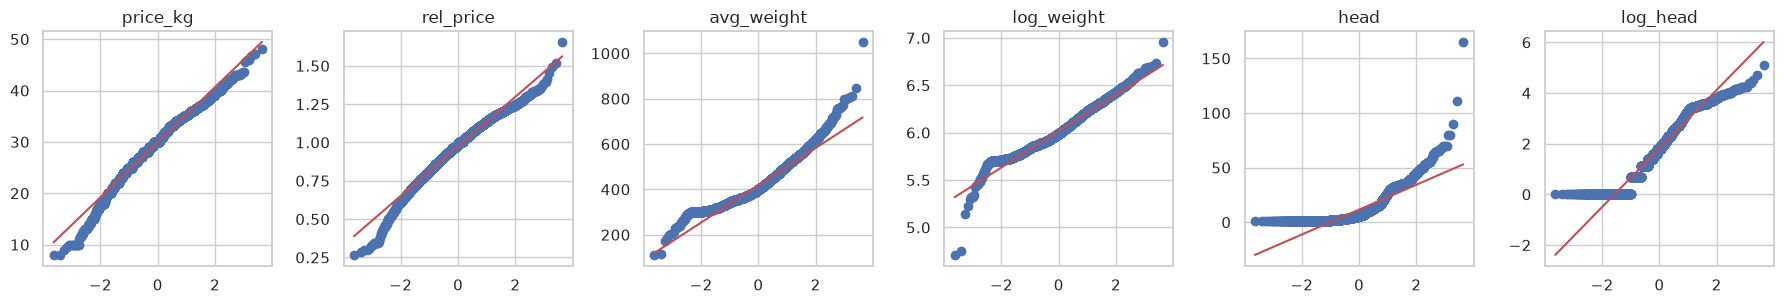

In [23]:
fig, axes = plt.subplots(1, 6, figsize=(18, 3.2))
sample = lots.sample(5000, random_state=42)
for ax, col in zip(axes, NORMALITY_VARS):
    stats.probplot(sample[col], dist="norm", plot=ax)
    ax.set(title=col, xlabel="", ylabel="")
plt.tight_layout()
plt.savefig(FIGURES / "03_qq_plots.png", dpi=120)
plt.show()

**Interpretation**

- With n = 5,000, Lilliefors rejects normality for **every** variable. With n = 50 the answer depends on the variable and the sample drawn.
  This is the sample-size effect explained in C4 and C7: the test result alone is not informative here.
- Q-Q plots: `price_kg` and `rel_price` follow the line in the centre but have a heavy left tail (lots sold far below the reference).
  `avg_weight` and `head` are clearly not normal.
- The logarithm brings the skewness of `head` from 2.1 to 0.0 and of `avg_weight` from 1.0 to 0.4.

**Consequences for the methods**

- Comparisons between groups: **non-parametric tests** (Kruskal-Wallis) and **medians**.
- Correlations: **Spearman** next to Pearson.
- Linear models: use `log_head` and `log_weight`. Tree models do not need the transformation.

### 2.6 Categorical variables and class balance (C2, C3)

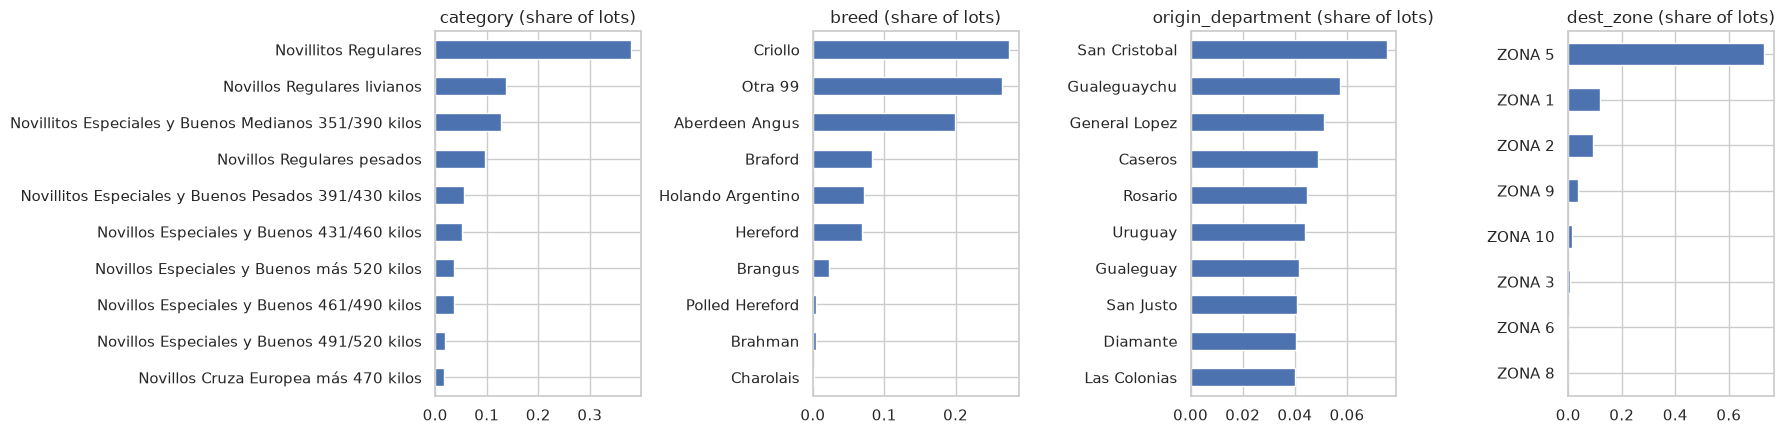

Levels per variable:
category             16
breed                21
origin_province       4
origin_department    71
dest_zone             8
dtype: int64

premium = 1: 44.4%


In [24]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, col in zip(axes, ["category", "breed", "origin_department", "dest_zone"]):
    share = lots[col].str.replace("Bovino ", "").value_counts(normalize=True).head(10).sort_values()
    share.plot.barh(ax=ax)
    ax.set(title=f"{col} (share of lots)", ylabel="")
plt.tight_layout()
plt.savefig(FIGURES / "04_categorical_frequencies.png", dpi=120)
plt.show()

print("Levels per variable:")
print(lots[["category", "breed", "origin_province", "origin_department", "dest_zone"]].nunique())
print(f"\npremium = 1: {lots['premium'].mean():.1%}")

**Interpretation**

- **Category:** 16 levels, but "Novillitos Regulares" alone is 38% of the lots. Category names already include the quality
  (Especiales y Buenos / Regulares) and the weight range.
- **Breed:** "Bovino Criollo" and "Otra 99" (other/unknown) are more than half of the lots. Angus, Braford, Holando and Hereford follow.
- **Destination:** 73% of the lots are slaughtered in zone 5 (their own region); most of the rest goes to Buenos Aires (zones 1 and 2).
- **Class balance:** 44% premium / 56% not. Slightly unbalanced because the reference is national and the Litoral sells a bit below it.
  Accuracy is still usable, with ROC AUC as the main metric.

---
## 3. Bivariate analysis

### 3.1 Numeric vs numeric: correlation (C5)

Pearson measures linear association; Spearman measures monotonic association and is robust to outliers and skew.

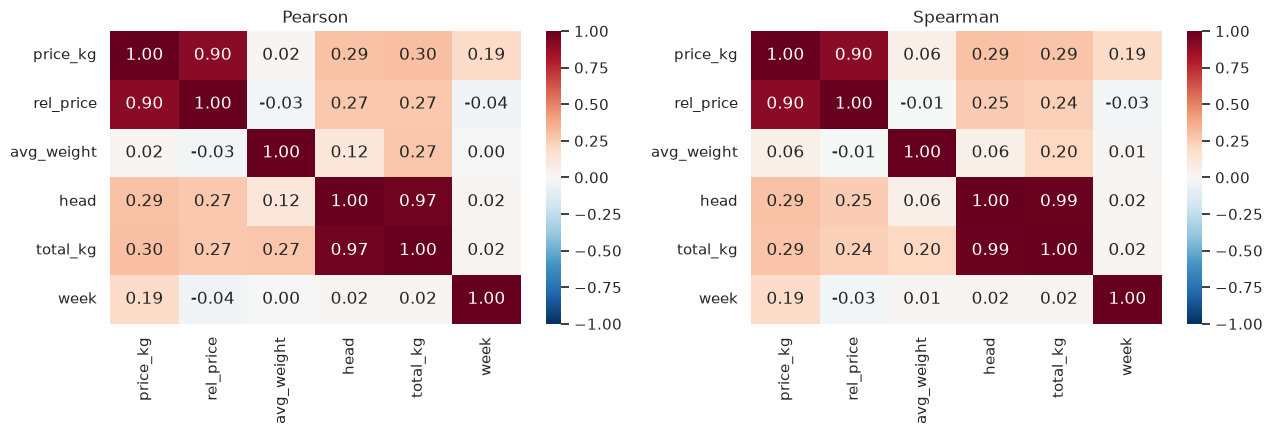

In [25]:
CORR_VARS = ["price_kg", "rel_price", "avg_weight", "head", "total_kg", "week"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, method in zip(axes, ["pearson", "spearman"]):
    sns.heatmap(lots[CORR_VARS].corr(method=method), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
    ax.set_title(method.capitalize())
plt.tight_layout()
plt.savefig(FIGURES / "05_correlations.png", dpi=120)
plt.show()

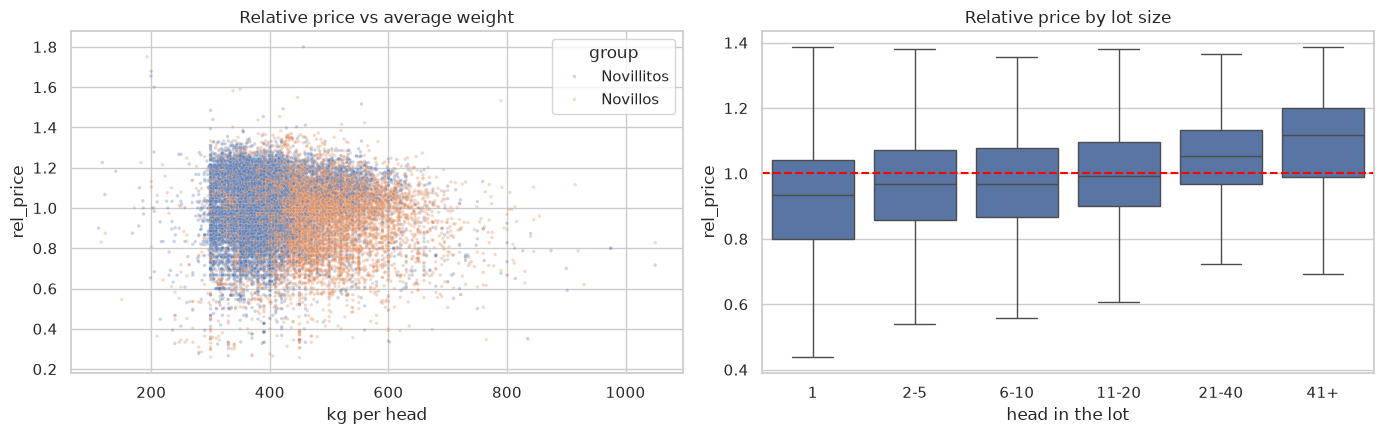

,size,median
head,,
1,3792,0.93
2-5,7679,0.97
6-10,4484,0.97
11-20,3636,0.99
21-40,4059,1.05
41+,816,1.12


In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.scatterplot(data=lots, x="avg_weight", y="rel_price", hue="group", s=6, alpha=0.3, ax=axes[0])
axes[0].set(title="Relative price vs average weight", xlabel="kg per head")

size_bins = pd.cut(lots["head"], [0, 1, 5, 10, 20, 40, 1000], labels=["1", "2-5", "6-10", "11-20", "21-40", "41+"])
sns.boxplot(x=size_bins, y=lots["rel_price"], showfliers=False, ax=axes[1])
axes[1].axhline(1, color="red", linestyle="--")
axes[1].set(title="Relative price by lot size", xlabel="head in the lot")
plt.tight_layout()
plt.savefig(FIGURES / "06_rel_price_vs_weight_and_size.png", dpi=120)
plt.show()

lots.groupby(size_bins, observed=True)["rel_price"].agg(["size", "median"]).round(3)

**Interpretation**

- `price_kg` and `rel_price` are almost the same information (Spearman 0.90): once the category is fixed, most of the price variation
  is the variation against the typical price.
- `head` and `total_kg` are redundant (0.99): keep `head` and `avg_weight`, drop `total_kg` (collinearity).
- **Lot size is the strongest numeric signal** (Spearman 0.25 with `rel_price`): single animals sell about 7% below the typical price,
  lots of 21–40 head about 5% above and lots of more than 40 head about 12% above.
  The relation is monotonic but not a straight line, which is why Spearman is higher than Pearson.
- **Weight does not correlate** with the relative price (-0.01): the weight is already inside the category name.
- `week` correlates with `price_kg` (0.19, inflation) but not with `rel_price` (-0.03), as intended.

### 3.2 Numeric vs categorical: comparison of groups (C6, C7)

- **Levene**: equal variances (assumption of ANOVA).
- **ANOVA** (parametric) and **Kruskal-Wallis** (non-parametric).
- **Effect size**: eta squared (ANOVA) and epsilon squared (Kruskal-Wallis) = share of the variability explained by the groups.
  With thousands of lots almost every p-value is 0 (C7: power grows with the sample size), so the decision uses the effect size.
  Usual reading: 0.01 small, 0.06 medium, 0.14 large.

In [27]:
def compare_groups(data, target, factor, min_size=30):
    groups = [g[target].to_numpy() for _, g in data.groupby(factor) if len(g) >= min_size]
    n, k = sum(len(g) for g in groups), len(groups)
    everything = np.concatenate(groups)
    between = sum(len(g) * (g.mean() - everything.mean()) ** 2 for g in groups)
    h_stat, kw_p = stats.kruskal(*groups)
    return {
        "target": target, "factor": factor, "groups": k,
        "Levene p": stats.levene(*groups).pvalue,
        "ANOVA p": stats.f_oneway(*groups).pvalue,
        "Kruskal-Wallis p": kw_p,
        "eta squared": between / ((everything - everything.mean()) ** 2).sum(),
        "epsilon squared": (h_stat - k + 1) / (n - k),
    }


FACTORS = ["category", "group", "breed", "origin_province", "origin_department", "dest_zone", "weekday", "week"]
effects = pd.DataFrame([compare_groups(lots, target, factor)
                        for target in ["price_kg", "rel_price"] for factor in FACTORS])
effects.set_index(["target", "factor"]).round(3)

groups  Levene p  ANOVA p  Kruskal-Wallis p  \
target    factor                                                           
price_kg  category               16      0.00     0.00              0.00   
          group                   2      0.00     0.00              0.00   
          breed                  11      0.00     0.00              0.00   
          origin_province         4      0.00     0.00              0.00   
          origin_department      49      0.00     0.00              0.00   
          dest_zone               6      0.00     0.00              0.00   
          weekday                 7      0.00     0.00              0.00   
          week                   26      0.00     0.00              0.00   
rel_price category               16      0.00     0.00              0.00   
          group                   2      0.00     0.00              0.00   
          breed                  11      0.00     0.00              0.00   
          origin_province         4      0.00     0.00              0.00   
          origin_department      49      0.00     0.00              0.00   
          dest_zone               6      0.00     0.00              0.00   
          weekday                 7      0.00     0.00              0.00   
          week                   26      0.00     0.00              0.00   

                             eta squared  epsilon squared  
target    factor                                           
price_kg  category                  0.12             0.09  
          group                     0.01             0.00  
          breed                     0.04             0.05  
          origin_province           0.02             0.01  
          origin_department         0.10             0.09  
          dest_zone                 0.06             0.05  
          weekday                   0.00             0.00  
          week                      0.05             0.05  
rel_price category                  0.01             0.01  
          group                     0.01             0.01  
          breed                     0.03             0.04  
          origin_province           0.01             0.00  
          origin_department         0.09             0.08  
          dest_zone                 0.03             0.03  
          weekday                   0.00             0.00  
          week                      0.01             0.00

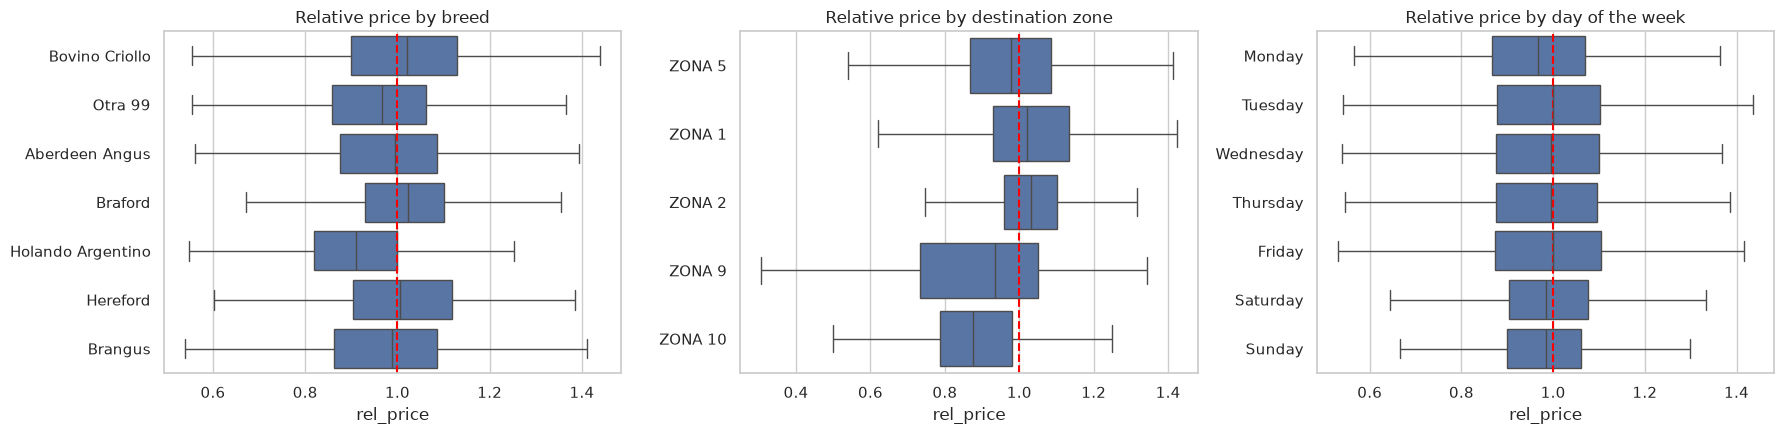

size  median
dest_zone ZONA 1      2933    1.02
          ZONA 10      323    0.88
          ZONA 2      2229    1.03
          ZONA 5     17911    0.98
          ZONA 9       902    0.93
weekday   Monday      4443    0.97
          Tuesday     5346    1.00
          Wednesday   5326    0.99
          Thursday    3813    0.99
          Friday      2896    1.00
          Saturday    1692    0.98
          Sunday       950    0.98

In [28]:
WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
MAIN_BREEDS = ["Bovino Criollo", "Otra 99", "Aberdeen Angus", "Braford", "Holando Argentino", "Hereford", "Brangus"]
MAIN_ZONES = ["ZONA 5", "ZONA 1", "ZONA 2", "ZONA 9", "ZONA 10"]

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
sns.boxplot(data=lots[lots["breed"].isin(MAIN_BREEDS)], x="rel_price", y="breed", order=MAIN_BREEDS, showfliers=False, ax=axes[0])
sns.boxplot(data=lots[lots["dest_zone"].isin(MAIN_ZONES)], x="rel_price", y="dest_zone", order=MAIN_ZONES, showfliers=False, ax=axes[1])
sns.boxplot(data=lots, x="rel_price", y="weekday", order=WEEKDAYS, showfliers=False, ax=axes[2])
for ax, title in zip(axes, ["breed", "destination zone", "day of the week"]):
    ax.axvline(1, color="red", linestyle="--")
    ax.set(title=f"Relative price by {title}", ylabel="")
plt.tight_layout()
plt.savefig(FIGURES / "07_rel_price_by_factor.png", dpi=120)
plt.show()

pd.concat({
    "dest_zone": lots[lots["dest_zone"].isin(MAIN_ZONES)].groupby("dest_zone")["rel_price"].agg(["size", "median"]),
    "weekday": lots.groupby("weekday")["rel_price"].agg(["size", "median"]).reindex(WEEKDAYS),
}).round(3)

**Interpretation**

- Levene rejects equal variances and normality does not hold: **Kruskal-Wallis is the appropriate test**. The effect size decides.
- On the **relative price**, the factors rank as follows (epsilon squared):
  origin department 0.08 (medium), **breed 0.04**, destination zone 0.03, category 0.01, province, day of the week and week below 0.01.
- **Where the lot is sold matters:** lots sent to Buenos Aires (zones 1 and 2) are paid about 2–3% above the typical price, while
  lots slaughtered in their own zone 5 are about 2% below, and those sent north (zones 9 and 10) clearly below.
- **When:** Monday is the weakest day (median about 3% below the reference); Tuesday and Friday are at the reference. A real but small effect.
- **Province** alone explains almost nothing; the **department** explains much more, so location should enter the model at department level.

### 3.3 Which breeds are paid above the typical price? (question 3)

Median relative price and share of lots sold at a premium, for breeds with at least 100 lots.
The **risk ratio** (ML Zoomcamp module 3) is the premium rate of the breed divided by the global rate.

In [29]:
def breed_table(data, min_lots=100):
    table = data.groupby("breed").agg(
        lots=("rel_price", "size"),
        median_rel_price=("rel_price", "median"),
        premium_rate=("premium", "mean"),
        median_head=("head", "median"),
    )
    table["risk_ratio"] = table["premium_rate"] / data["premium"].mean()
    return table[table["lots"] >= min_lots].sort_values("median_rel_price", ascending=False).round(3)


breed_table(lots)

,lots,median_rel_price,premium_rate,median_head,risk_ratio
breed,,,,,
Brahman,105,1.15,0.68,4.00,1.52
Polled Hereford,111,1.09,0.72,5.00,1.62
Braford,2030,1.02,0.55,8.00,1.24
Bovino Criollo,6719,1.02,0.53,8.00,1.19
Hereford,1690,1.00,0.51,5.00,1.14
Aberdeen Angus,4881,0.99,0.44,7.00,0.99
Brangus,554,0.99,0.45,5.00,1.01
Otra 99,6500,0.97,0.37,6.00,0.83
Holando Argentino,1745,0.91,0.21,5.00,0.48


In [30]:
# The same table for Entre Ríos only
breed_table(lots[lots["origin_province"] == "Entre Rios"])

,lots,median_rel_price,premium_rate,median_head,risk_ratio
breed,,,,,
Polled Hereford,110,1.10,0.73,5.00,1.58
Braford,607,1.07,0.70,7.00,1.52
Bovino Criollo,2662,1.06,0.59,11.00,1.28
Hereford,1041,1.03,0.54,5.00,1.17
Aberdeen Angus,2174,0.97,0.40,8.00,0.86
Holando Argentino,391,0.92,0.31,4.00,0.67
Otra 99,2304,0.91,0.28,5.00,0.61


**Post-hoc comparison (C7).** Kruskal-Wallis says "at least one breed differs", not which ones.
The class proposes pairwise Mann-Whitney tests with a corrected significance level (Bonferroni: p multiplied by the number of pairs).

In [31]:
from itertools import combinations

POSTHOC_BREEDS = ["Braford", "Bovino Criollo", "Hereford", "Aberdeen Angus", "Holando Argentino"]
pairs_tested = list(combinations(POSTHOC_BREEDS, 2))
rows = []
for a, b in pairs_tested:
    x = lots.loc[lots["breed"] == a, "rel_price"]
    y = lots.loc[lots["breed"] == b, "rel_price"]
    u_stat, p = stats.mannwhitneyu(x, y)
    rows.append({
        "breed A": a, "breed B": b,
        "median A - median B": x.median() - y.median(),
        "P(A > B)": u_stat / (len(x) * len(y)),        # effect size: 0.5 = no difference
        "p (Bonferroni)": min(p * len(pairs_tested), 1),
    })
pd.DataFrame(rows).round(3)

,breed A,breed B,median A - median B,P(A > B),p (Bonferroni)
0,Braford,Bovino Criollo,0.00,0.49,1.00
1,Braford,Hereford,0.02,0.50,1.00
2,Braford,Aberdeen Angus,0.03,0.55,0.00
3,Braford,Holando Argentino,0.11,0.70,0.00
4,Bovino Criollo,Hereford,0.01,0.51,1.00
5,Bovino Criollo,Aberdeen Angus,0.03,0.55,0.00
6,Bovino Criollo,Holando Argentino,0.11,0.69,0.00
7,Hereford,Aberdeen Angus,0.01,0.55,0.00
8,Hereford,Holando Argentino,0.10,0.70,0.00
9,Aberdeen Angus,Holando Argentino,0.09,0.65,0.00


**Interpretation**

- **Above the typical price:** Braford and "Bovino Criollo" (about +2%, 53–55% of their lots at a premium). Polled Hereford and Brahman
  look higher, but with only about 100 lots each.
- **At the reference:** Hereford, Aberdeen Angus and Brangus (0.99–1.00).
- **Below:** Holando Argentino, a dairy breed (about -9%, only 21% of its lots at a premium) and "Otra 99" (-3%).
- **Entre Ríos alone** shows larger gaps: Braford +7%, Criollo +6%, Hereford +3%, Angus -3%, Holando -8%, "Otra 99" -9%.
- Post-hoc tests: Braford, Criollo and Hereford **do not differ** from each other (p = 1). Each of them is slightly above Angus
  (P(A > B) = 0.55, small effect) and clearly above Holando (0.65–0.70, moderate effect).

**Limits of this answer**

- Breed is **self-declared** in the tax settlement, and more than half of the lots are "Criollo" or "Otra 99".
- Lot size differs by breed (see `median_head`), and lot size also raises the price: part of the breed gap can come from there.
  The models will separate both effects.
- This is a price **premium**, not a profit margin: the data has no costs.

### 3.4 Categorical vs categorical: association (C8)

Chi-square tests independence in a contingency table; **Cramér's V** measures the strength (0 = independent, 1 = perfect).
C8 notes that values above 0.6 are rare in practice and 0.3 is already an intermediate association.
**Mutual information** (ML Zoomcamp module 3) measures how much knowing a variable tells about `premium`.

In [32]:
from sklearn.metrics import mutual_info_score


def cramers_v(data, a, b):
    table = pd.crosstab(data[a], data[b])
    chi2, p, _, expected = stats.chi2_contingency(table)
    return {
        "variables": f"{a} x {b}", "chi-square p": p,
        "cells with expected < 5": (expected < 5).mean(),
        "Cramer's V": np.sqrt(chi2 / (table.to_numpy().sum() * (min(table.shape) - 1))),
    }


CATEGORICAL = ["category", "breed", "origin_province", "origin_department", "dest_zone", "weekday"]
association = pd.DataFrame([cramers_v(lots, "premium", col) for col in CATEGORICAL]).set_index("variables")
association["mutual information"] = [mutual_info_score(lots["premium"], lots[col]) for col in CATEGORICAL]
association.sort_values("Cramer's V", ascending=False).round(3)

,chi-square p,cells with expected < 5,Cramer's V,mutual information
variables,,,,
premium x origin_department,0.00,0.20,0.26,0.04
premium x breed,0.00,0.38,0.20,0.02
premium x dest_zone,0.00,0.12,0.14,0.01
premium x category,0.00,0.00,0.10,0.01
premium x weekday,0.00,0.00,0.07,0.00
premium x origin_province,0.00,0.00,0.03,0.00


In [33]:
pd.DataFrame([cramers_v(lots, a, b) for a, b in
              [("breed", "origin_province"), ("breed", "category"), ("origin_province", "dest_zone")]]).set_index("variables").round(3)

,chi-square p,cells with expected < 5,Cramer's V
variables,,,
breed x origin_province,0.00,0.54,0.18
breed x category,0.00,0.63,0.14
origin_province x dest_zone,0.00,0.28,0.38


**Interpretation**

- Ranking of association with `premium`: **origin department (V ≈ 0.25), breed (0.20), destination zone (0.14), category (0.10)**,
  day of the week (0.07) and province (0.03). Mutual information gives the same order.
- All associations are weak to intermediate: no variable alone separates premium lots, but department and breed are clearly informative.
- C8 asks for fewer than 20% of the cells with an expected frequency below 5. Tables with rare breeds or small departments can miss it,
  so their V is indicative.
- Breed is associated with the province and the category: its effect has to be read together with them (next section).

---
## 4. Multivariate analysis

*Course reference: C10 (multivariate analysis, outliers), C11 (principal components).*

### 4.1 Breed, province and destination together

Is a breed paid more everywhere, or only because of where it is raised and sold?
Median relative price by breed and origin province, and by breed and destination (cells with at least 50 lots).

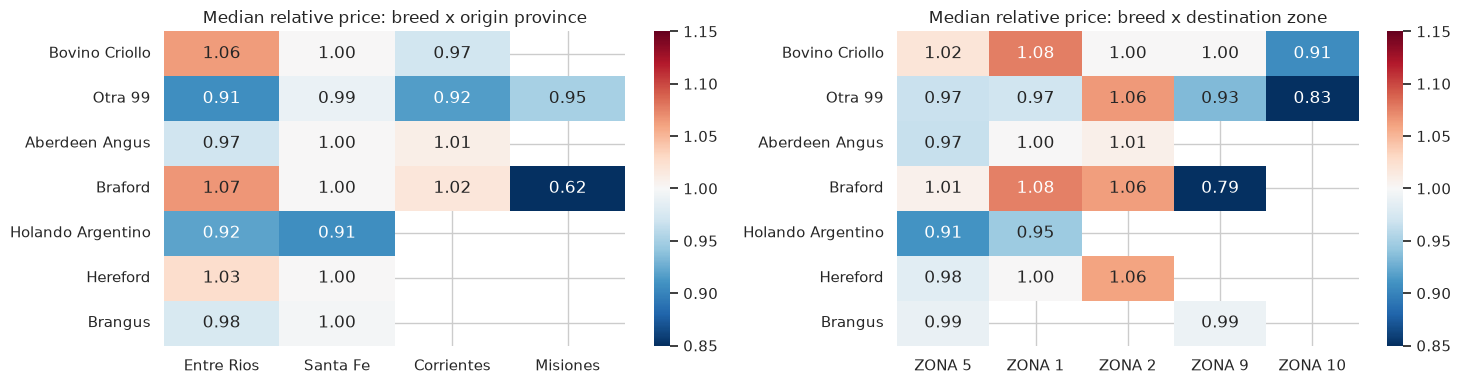

In [34]:
def median_heatmap(data, rows, cols, row_order, col_order, ax, min_lots=50):
    size = data.pivot_table(index=rows, columns=cols, values="rel_price", aggfunc="size")
    median = data.pivot_table(index=rows, columns=cols, values="rel_price", aggfunc="median")
    table = median.where(size >= min_lots).reindex(index=row_order, columns=col_order)
    sns.heatmap(table, annot=True, fmt=".2f", cmap="RdBu_r", center=1, vmin=0.85, vmax=1.15, ax=ax)
    ax.set(xlabel="", ylabel="")


fig, axes = plt.subplots(1, 2, figsize=(15, 4))
median_heatmap(lots, "breed", "origin_province", MAIN_BREEDS, PROVINCES, axes[0])
median_heatmap(lots, "breed", "dest_zone", MAIN_BREEDS, MAIN_ZONES, axes[1])
axes[0].set_title("Median relative price: breed x origin province")
axes[1].set_title("Median relative price: breed x destination zone")
plt.tight_layout()
plt.savefig(FIGURES / "08_breed_by_province_and_destination.png", dpi=120)
plt.show()

### 4.2 Multivariate outliers: Mahalanobis distance (C10)

A lot can be normal in each variable and unusual in the combination. The Mahalanobis distance measures how far each lot is
from the centre, taking correlations into account. Following C10, a **robust** version is used.
Under normality the squared distance follows a chi-square distribution; the 99.9% quantile is the threshold.

In [35]:
from sklearn.covariance import MinCovDet

MAHA_VARS = ["rel_price", "log_weight", "log_head"]
robust = MinCovDet(random_state=42).fit(lots[MAHA_VARS])
lots["mahalanobis_sq"] = robust.mahalanobis(lots[MAHA_VARS])
threshold = stats.chi2.ppf(0.999, df=len(MAHA_VARS))
lots["multivariate_outlier"] = lots["mahalanobis_sq"] > threshold

print(f"Threshold: {threshold:.1f}  Outliers: {lots['multivariate_outlier'].sum():,} ({lots['multivariate_outlier'].mean():.2%})")
lots.groupby("multivariate_outlier")[["price_kg", "rel_price", "avg_weight", "head"]].median().round(2)

Threshold: 16.3  Outliers: 252 (1.03%)


,price_kg,rel_price,avg_weight,head
multivariate_outlier,,,,
False,30.00,0.99,400.00,6.00
True,18.70,0.61,470.00,1.00


### 4.3 Principal components (C11)

C11 states that PCA only makes sense when the variables are **strongly correlated** and recommends the correlation matrix.
Bartlett's sphericity test checks whether the correlation matrix differs from the identity.

In [36]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

PCA_VARS = ["price_kg", "log_weight", "log_head", "week"]
standardized = StandardScaler().fit_transform(lots[PCA_VARS])

corr = np.corrcoef(standardized, rowvar=False)
n, p = standardized.shape
bartlett = -(n - 1 - (2 * p + 5) / 6) * np.log(np.linalg.det(corr))
print(f"Determinant of the correlation matrix: {np.linalg.det(corr):.3f} (1 = no correlation at all)")
print(f"Bartlett chi-square = {bartlett:,.0f}, p = {stats.chi2.sf(bartlett, p * (p - 1) / 2):.3g}")

pca = PCA().fit(standardized)
pd.DataFrame({
    "eigenvalue": pca.explained_variance_,
    "variance explained": pca.explained_variance_ratio_,
    "cumulative": pca.explained_variance_ratio_.cumsum(),
}, index=[f"PC{i + 1}" for i in range(p)]).round(3)

Determinant of the correlation matrix: 0.875 (1 = no correlation at all)
Bartlett chi-square = 3,280, p = 0


,eigenvalue,variance explained,cumulative
PC1,1.37,0.34,0.34
PC2,1.01,0.25,0.59
PC3,0.96,0.24,0.84
PC4,0.66,0.16,1.00


**Interpretation of the multivariate analysis**

- **Breed, province and destination (4.1).** The breed gaps are **mostly an Entre Ríos pattern**: in Santa Fe every main breed is at the
  reference (0.99–1.00) except Holando (0.91). Holando is below everywhere it appears: that result is robust.
  The destination adds to it: Criollo and Braford sent to zone 1 (Buenos Aires) get about +8%, while the same breeds slaughtered in zone 5
  are near the reference. Breed, origin and destination **interact**, which a tree model captures naturally and a linear model does not.
- **Outliers (4.2).** About 1% of the lots are multivariate outliers: typically a single heavy animal sold at about 60% of the typical price.
  They look like real sales (animals in poor condition), not typing errors, so they are **kept**. They explain the left tail seen in 2.4.
- **PCA (4.3).** The determinant of the correlation matrix is 0.88, close to 1: the numeric variables are almost uncorrelated.
  The first component explains only 34% and three of four are needed to reach 84%. **PCA does not reduce the problem**, and most features
  are categorical, where PCA does not apply. It is not used.

---
## 5. Conclusions and modelling dataset

### 5.1 What the EDA showed

| Finding | Evidence | Consequence for the models |
|---|---|---|
| Litoral steers sell slightly below the national reference | Median `rel_price` 0.99, 44% premium | Slightly unbalanced classes; use ROC AUC |
| Lot size is the main numeric signal | Spearman 0.25, stepwise medians | Use `log_head`; non-linear effect favours trees |
| Weight adds little beyond the category | Spearman -0.01 | Keep it, expect low importance |
| Location matters at department level, not province level | Epsilon squared 0.08 vs 0.004 | Use `origin_department` (about 70 levels) |
| Breed and destination have small to medium effects | Epsilon squared 0.04 and 0.03 | Keep both; they interact |
| Skewed variables, unequal variances | Skewness, Q-Q plots, Levene | Medians, non-parametric tests, log for linear models |
| `total_kg` ≈ `head` | r = 0.99 | Drop `total_kg` |
| PCA does not reduce the problem | Weak correlations, mostly categorical features | Not used |

### 5.2 Methods for each question

**Question 1 — How much will a lot be paid per kg?** Regression on `rel_price`; the price in pesos is `rel_price × typical_price`.
Baseline: `rel_price` = training median. Models: Ridge regression, decision tree, Random Forest, XGBoost. Metric: RMSE (and MAE in ARS/kg).

**Question 2 — Will the lot sell above the typical price?** Binary classification on `premium`.
Baseline: majority class. Models: logistic regression, decision tree, Random Forest, XGBoost. Metric: ROC AUC, plus accuracy, precision and recall.
The price columns must **not** be features (they define the target).

**Question 3 — Which breeds are paid above the typical price?** Comparison of groups (Kruskal-Wallis, effect size, pairwise Mann-Whitney),
read together with province and destination (4.1), and confirmed later with the feature importance of the tree models.

### 5.3 Features available when a lot is offered

`category`, `breed`, `origin_province`, `origin_department`, `dest_zone`, `head`, `avg_weight`, `weekday`.
`week` is kept only to split the data by time.

### 5.4 Train / validation / test split by time

Lots are split by week so the models are evaluated on weeks they have not seen: weeks 1–15 for training,
16–20 for validation and 21–26 for testing (about 60% / 20% / 20%).

In [37]:
TRAIN_UNTIL_WEEK, VALIDATION_UNTIL_WEEK = 15, 20

lots["split"] = np.select(
    [lots["week"] <= TRAIN_UNTIL_WEEK, lots["week"] <= VALIDATION_UNTIL_WEEK],
    ["train", "validation"], default="test")

lots.groupby("split").agg(
    lots=("premium", "size"), share=("premium", lambda s: len(s) / len(lots)),
    first_day=("date", lambda s: s.min().date()), last_day=("date", lambda s: s.max().date()),
    premium_rate=("premium", "mean"), median_rel_price=("rel_price", "median"),
).reindex(["train", "validation", "test"])

,lots,share,first_day,last_day,premium_rate,median_rel_price
split,,,,,,
train,14462,0.59,2018-01-01,2018-04-15,0.45,0.99
validation,4501,0.18,2018-04-16,2018-05-20,0.44,0.99
test,5503,0.22,2018-05-21,2018-06-30,0.44,0.98


In [38]:
MODEL_COLUMNS = ["date", "week", "split",
                 "category", "group", "breed", "origin_province", "origin_department", "dest_zone", "weekday",
                 "head", "avg_weight",
                 "price_kg", "typical_price", "rel_price", "premium"]
lots[MODEL_COLUMNS].to_csv(DATA_PROCESSED / "steers_litoral.csv.gz", index=False)
print(f"Saved {len(lots):,} lots to {DATA_PROCESSED / 'steers_litoral.csv.gz'}")
lots[MODEL_COLUMNS].head()

Saved 24,466 lots to ../data/processed/steers_litoral.csv.gz


,date,week,split,category,group,breed,origin_province,origin_department,dest_zone,weekday,head,avg_weight,price_kg,typical_price,rel_price,premium
0,2018-01-01,1,train,Bovino Novillitos Regulares,Novillitos,Aberdeen Angus,Entre Rios,Gualeguaychu,ZONA 2,Monday,7,312.86,20.00,28.00,0.71,0
16,2018-01-01,1,train,Bovino Novillitos Regulares,Novillitos,Aberdeen Angus,Entre Rios,Gualeguay,ZONA 1,Monday,16,386.88,25.65,28.00,0.92,0
17,2018-01-01,1,train,Bovino Novillos Regulares livianos,Novillos,Aberdeen Angus,Entre Rios,Gualeguay,ZONA 1,Monday,1,460.00,24.20,27.50,0.88,0
18,2018-01-01,1,train,Bovino Novillos Especiales y Buenos 431/460 kilos,Novillos,Otra 99,Entre Rios,Colon,ZONA 5,Monday,10,390.00,33.19,30.05,1.10,1
38,2018-01-01,1,train,Bovino Novillos Overos Negros más de 500 kilos,Novillos,Bovino Criollo,Santa Fe,Las Colonias,ZONA 5,Monday,26,683.85,29.23,26.63,1.10,1


---
## 6. Model training and selection — will the lot sell at a premium?

This section follows the module 6 sequence: a baseline, a linear model, a single decision tree
(shown first **without limits** to see overfitting, then tuned), Random Forest, XGBoost, and the
final selection evaluated once on the test set.

### 6.1 Feature matrix

Features available when a lot is offered: `category`, `breed`, `origin_province`, `origin_department`,
`dest_zone`, `weekday`, `log_head`, `log_weight`. The price columns are excluded: they define the target.
Categorical variables are one-hot encoded with `DictVectorizer`, as in the course.

In [39]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
import xgboost as xgb

model_df = pd.read_csv(DATA_PROCESSED / "steers_litoral.csv.gz", parse_dates=["date"])
model_df["log_head"] = np.log(model_df["head"])
model_df["log_weight"] = np.log(model_df["avg_weight"])

FEATURES = ["category", "breed", "origin_province", "origin_department",
            "dest_zone", "weekday", "log_head", "log_weight"]
TARGET = "premium"


def features_and_target(mask):
    part = model_df[mask]
    return part[FEATURES].to_dict(orient="records"), part[TARGET].to_numpy()


train_dicts, y_train = features_and_target(model_df["split"] == "train")
val_dicts, y_val = features_and_target(model_df["split"] == "validation")
test_dicts, y_test = features_and_target(model_df["split"] == "test")

dv = DictVectorizer(sparse=True)
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)
X_test = dv.transform(test_dicts)

print(f"Train: {X_train.shape[0]:,} lots, {X_train.shape[1]} features after one-hot encoding")
print(f"Premium rate — train: {y_train.mean():.3f}, validation: {y_val.mean():.3f}, test: {y_test.mean():.3f}")

Train: 14,462 lots, 122 features after one-hot encoding
Premium rate — train: 0.447, validation: 0.437, test: 0.444


### 6.2 Baseline

The simplest possible model predicts the majority class ("not premium") for every lot.
Any model worth keeping must beat its accuracy, and an ROC AUC of 0.5 (random ranking).

In [40]:
majority_accuracy = max(1 - y_val.mean(), y_val.mean())
print(f"Majority-class accuracy on validation: {majority_accuracy:.3f}")
print("ROC AUC of a constant prediction: 0.500")

Majority-class accuracy on validation: 0.563
ROC AUC of a constant prediction: 0.500


### 6.3 Logistic regression 

The linear benchmark. `C` controls regularization (smaller = stronger).

In [41]:
logistic_scores = {}
for C in [0.01, 0.1, 1, 10]:
    model = LogisticRegression(C=C, max_iter=2000)
    model.fit(X_train, y_train)
    logistic_scores[C] = roc_auc_score(y_val, model.predict_proba(X_val)[:, 1])

logistic_scores = pd.Series(logistic_scores).rename_axis("C")
best_C = logistic_scores.idxmax()
logistic_auc = logistic_scores.max()
logistic_scores.map("{:.4f}".format).to_frame("validation AUC")

,validation AUC
C,
0.01,0.7044
0.10,0.7148
1.00,0.7147
10.00,0.7145


### 6.4 Decision tree 

First a tree **without limits**, to see what the course warns about:

In [42]:
tree = DecisionTreeClassifier(random_state=1)
tree.fit(X_train, y_train)
print(f"Depth reached: {tree.get_depth()}")
print(f"Train AUC: {roc_auc_score(y_train, tree.predict_proba(X_train)[:, 1]):.4f}")
print(f"Validation AUC: {roc_auc_score(y_val, tree.predict_proba(X_val)[:, 1]):.4f}")

Depth reached: 45
Train AUC: 0.9999
Validation AUC: 0.7006


The tree memorizes the training data (AUC ≈ 1.0) but does much worse on lots it has not seen: **overfitting**.
The course's recipe is to tune `max_depth` first and then `min_samples_leaf`.

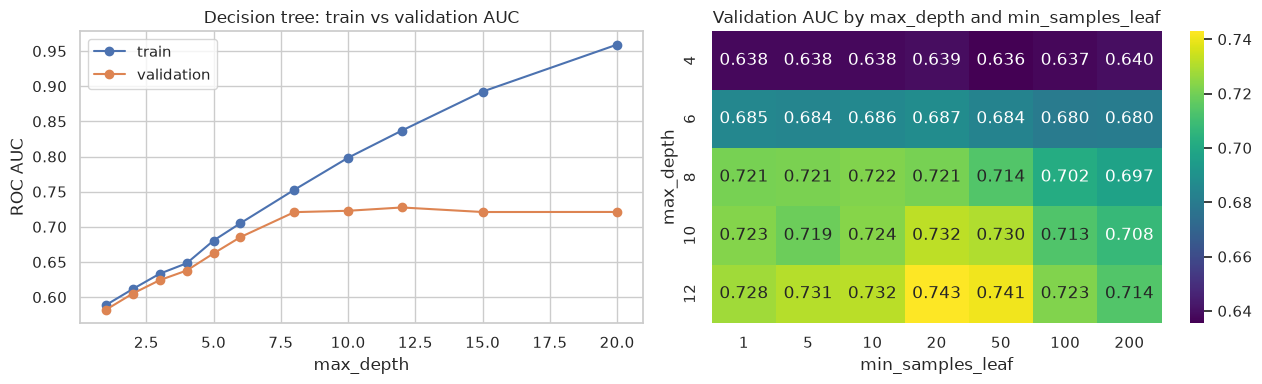

Best tree: max_depth=12, min_samples_leaf=20, validation AUC 0.7429


In [43]:
depth_rows = []
for depth in [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20]:
    model = DecisionTreeClassifier(max_depth=depth, random_state=1).fit(X_train, y_train)
    depth_rows.append({
        "max_depth": depth,
        "train": roc_auc_score(y_train, model.predict_proba(X_train)[:, 1]),
        "validation": roc_auc_score(y_val, model.predict_proba(X_val)[:, 1]),
    })
depth_scores = pd.DataFrame(depth_rows).set_index("max_depth")

leaf_rows = []
for depth in [4, 6, 8, 10, 12]:
    for leaf in [1, 5, 10, 20, 50, 100, 200]:
        model = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=leaf, random_state=1).fit(X_train, y_train)
        leaf_rows.append({"max_depth": depth, "min_samples_leaf": leaf,
                          "auc": roc_auc_score(y_val, model.predict_proba(X_val)[:, 1])})
leaf_grid = pd.DataFrame(leaf_rows).pivot(index="max_depth", columns="min_samples_leaf", values="auc")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
depth_scores.plot(ax=axes[0], marker="o")
axes[0].set(title="Decision tree: train vs validation AUC", ylabel="ROC AUC")
sns.heatmap(leaf_grid, annot=True, fmt=".3f", cmap="viridis", ax=axes[1])
axes[1].set_title("Validation AUC by max_depth and min_samples_leaf")
plt.tight_layout()
plt.savefig(FIGURES / "09_tree_tuning.png", dpi=120)
plt.show()

best_depth, best_leaf = leaf_grid.stack().idxmax()
tree_auc = leaf_grid.stack().max()
print(f"Best tree: max_depth={best_depth}, min_samples_leaf={best_leaf}, validation AUC {tree_auc:.4f}")

The gap between the train and validation curves grows with the depth — the picture of overfitting.
The tuned tree already beats the logistic regression: the interactions seen in the EDA are real.

**Reading the tree.** A shallow tree is not the best model, but it shows the rules in plain words —
useful to explain *why* a lot is likely to sell at a premium:

In [44]:
readable_tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=20, random_state=1).fit(X_train, y_train)
print(export_text(readable_tree, feature_names=list(dv.get_feature_names_out()), max_depth=3))

|--- log_head <= 3.31
|   |--- origin_department=Diamante <= 0.50
|   |   |--- breed=Holando Argentino <= 0.50
|   |   |   |--- class: 0
|   |   |--- breed=Holando Argentino >  0.50
|   |   |   |--- class: 0
|   |--- origin_department=Diamante >  0.50
|   |   |--- breed=Holando Argentino <= 0.50
|   |   |   |--- class: 1
|   |   |--- breed=Holando Argentino >  0.50
|   |   |   |--- class: 0
|--- log_head >  3.31
|   |--- log_weight <= 5.99
|   |   |--- dest_zone=ZONA 5 <= 0.50
|   |   |   |--- class: 0
|   |   |--- dest_zone=ZONA 5 >  0.50
|   |   |   |--- class: 1
|   |--- log_weight >  5.99
|   |   |--- breed=Otra 99 <= 0.50
|   |   |   |--- class: 1
|   |   |--- breed=Otra 99 >  0.50
|   |   |   |--- class: 1



### 6.5 Random Forest 

Many trees, each trained on a random sample of lots and features, voting together.
First the number of trees, then the depth controls.

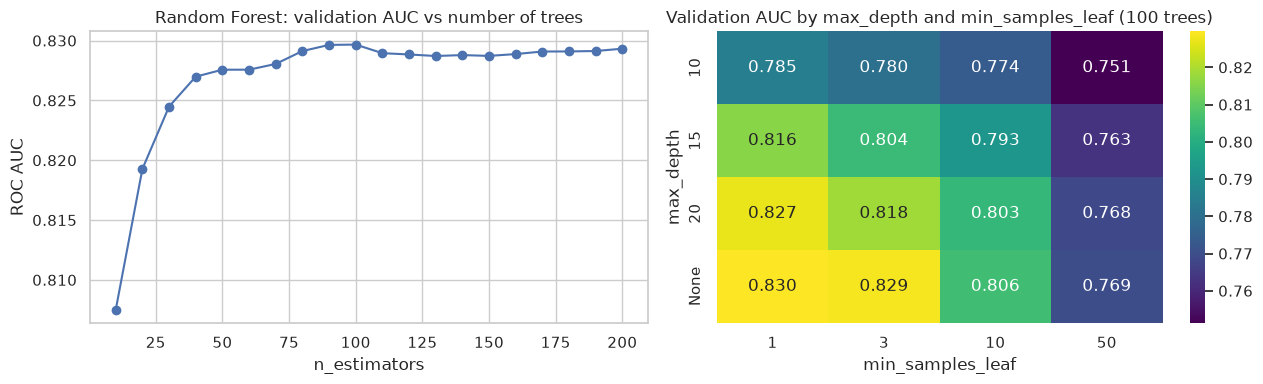

Best Random Forest: n_estimators=100, max_depth=None, min_samples_leaf=1, validation AUC 0.8297


In [45]:
n_rows = []
for n in range(10, 201, 10):
    model = RandomForestClassifier(n_estimators=n, random_state=1, n_jobs=-1).fit(X_train, y_train)
    n_rows.append({"n_estimators": n, "auc": roc_auc_score(y_val, model.predict_proba(X_val)[:, 1])})
n_scores = pd.DataFrame(n_rows).set_index("n_estimators")

rf_rows = []
for depth in [10, 15, 20, None]:
    for leaf in [1, 3, 10, 50]:
        model = RandomForestClassifier(n_estimators=100, max_depth=depth, min_samples_leaf=leaf,
                                       random_state=1, n_jobs=-1).fit(X_train, y_train)
        rf_rows.append({"max_depth": str(depth), "min_samples_leaf": leaf,
                        "auc": roc_auc_score(y_val, model.predict_proba(X_val)[:, 1])})
rf_grid = (pd.DataFrame(rf_rows).pivot(index="max_depth", columns="min_samples_leaf", values="auc")
           .reindex(["10", "15", "20", "None"]))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
n_scores.plot(ax=axes[0], marker="o", legend=False)
axes[0].set(title="Random Forest: validation AUC vs number of trees", ylabel="ROC AUC")
sns.heatmap(rf_grid, annot=True, fmt=".3f", cmap="viridis", ax=axes[1])
axes[1].set_title("Validation AUC by max_depth and min_samples_leaf (100 trees)")
plt.tight_layout()
plt.savefig(FIGURES / "10_rf_tuning.png", dpi=120)
plt.show()

rf_auc = rf_grid.loc["None", 1]
print(f"Best Random Forest: n_estimators=100, max_depth=None, min_samples_leaf=1, validation AUC {rf_auc:.4f}")

The AUC stabilizes at about 100 trees, and the best setting lets the trees grow fully
(`max_depth=None`, `min_samples_leaf=1`): each tree overfits, but averaging 100 of them cancels the noise —
exactly the idea of the ensemble.

### 6.6 XGBoost 

Gradient boosting: trees built one after another, each correcting the errors of the previous ones.
Tuned in the course order: learning rate `eta`, then `max_depth`, then `min_child_weight`,
always with early stopping on the validation set.

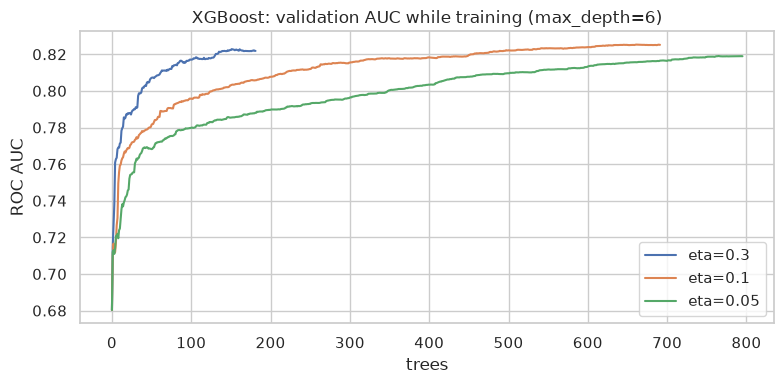

,best_rounds,validation AUC
eta,,
0.30,151,0.8228
0.10,661,0.8253
0.05,765,0.8190


In [46]:
feature_names = [name.replace("[", "(").replace("]", ")").replace("<", "lt")
                 for name in dv.get_feature_names_out()]
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=feature_names)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=feature_names)


def show_xgb(results, index_name):
    table = pd.DataFrame(results).T.rename_axis(index_name)
    table["best_rounds"] = table["best_rounds"].astype(int)
    table["validation AUC"] = table["validation AUC"].map("{:.4f}".format)
    return table


def train_xgb(eta, max_depth, min_child_weight):
    params = {"eta": eta, "max_depth": max_depth, "min_child_weight": min_child_weight,
              "objective": "binary:logistic", "eval_metric": "auc", "seed": 1, "verbosity": 0}
    history = {}
    model = xgb.train(params, dtrain, num_boost_round=1000,
                      evals=[(dval, "validation")], evals_result=history,
                      early_stopping_rounds=30, verbose_eval=False)
    return model, history["validation"]["auc"]


fig, ax = plt.subplots(figsize=(8, 4))
eta_results = {}
for eta in [0.3, 0.1, 0.05]:
    model, curve = train_xgb(eta, max_depth=6, min_child_weight=1)
    eta_results[eta] = {"best_rounds": model.best_iteration, "validation AUC": model.best_score}
    ax.plot(curve, label=f"eta={eta}")
ax.set(title="XGBoost: validation AUC while training (max_depth=6)", xlabel="trees", ylabel="ROC AUC")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES / "11_xgb_eta.png", dpi=120)
plt.show()

show_xgb(eta_results, "eta")

In [47]:
depth_results = {}
for max_depth in [3, 6, 10]:
    model, _ = train_xgb(eta=0.1, max_depth=max_depth, min_child_weight=1)
    depth_results[max_depth] = {"best_rounds": model.best_iteration, "validation AUC": model.best_score}
display(show_xgb(depth_results, "max_depth"))

mcw_results = {}
for mcw in [1, 10, 30]:
    model, _ = train_xgb(eta=0.1, max_depth=10, min_child_weight=mcw)
    mcw_results[mcw] = {"best_rounds": model.best_iteration, "validation AUC": model.best_score}
xgb_auc = max(row["validation AUC"] for row in mcw_results.values())
show_xgb(mcw_results, "min_child_weight")

,best_rounds,validation AUC
max_depth,,
3,879,0.8051
6,661,0.8253
10,286,0.8266


,best_rounds,validation AUC
min_child_weight,,
1,286,0.8266
10,264,0.8197
30,258,0.8124


### 6.7 Model comparison and selection

In [48]:
comparison = pd.DataFrame([
    {"model": "Baseline (majority class)", "validation AUC": 0.5, "settings": "-"},
    {"model": "Logistic regression", "validation AUC": logistic_auc, "settings": f"C={best_C}"},
    {"model": "Decision tree", "validation AUC": tree_auc,
     "settings": f"max_depth={best_depth}, min_samples_leaf={best_leaf}"},
    {"model": "Random Forest", "validation AUC": rf_auc,
     "settings": "n_estimators=100, max_depth=None, min_samples_leaf=1"},
    {"model": "XGBoost", "validation AUC": xgb_auc, "settings": "eta=0.1, max_depth=10, min_child_weight=1"},
]).set_index("model").sort_values("validation AUC", ascending=False)
comparison["validation AUC"] = comparison["validation AUC"].map("{:.4f}".format)
comparison

,validation AUC,settings
model,,
Random Forest,0.8297,"n_estimators=100, max_depth=None, min_samples_..."
XGBoost,0.8266,"eta=0.1, max_depth=10, min_child_weight=1"
Decision tree,0.7429,"max_depth=12, min_samples_leaf=20"
Logistic regression,0.7148,C=0.1
Baseline (majority class),0.5000,-


**Interpretation**

- Every model beats the baseline by a wide margin, and the ensembles clearly beat the single models.
- The jump from the logistic regression (0.715) to the ensembles (≈ 0.83) confirms the EDA: the signal is spread over
  **interactions** between department, breed, destination, lot size and weight, which a linear model cannot capture
  without hand-made terms.
- Random Forest (0.8297) and XGBoost (0.8266) are practically tied — the difference is within noise.
  With a tie, the **simpler model wins**: Random Forest with 100 fully grown trees, one hyperparameter choice instead of four.
- The small readable tree of 6.4 already tells the story in words: large lots of heavy animals are premium candidates,
  Holando lots are not, and some departments (Diamante, Entre Ríos) sell small lots at a premium.

### 6.8 Final model on the test set

Following module 6.10: the selected model is retrained on **train + validation** and evaluated
**once** on the test weeks (21–26), which it has never seen.

In [49]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, roc_curve

full_dicts, y_full = features_and_target(model_df["split"] != "test")
dv_final = DictVectorizer(sparse=True)
X_full = dv_final.fit_transform(full_dicts)
X_test_final = dv_final.transform(test_dicts)

final_model = RandomForestClassifier(n_estimators=100, random_state=1, n_jobs=-1).fit(X_full, y_full)
probability = final_model.predict_proba(X_test_final)[:, 1]
prediction = (probability >= 0.5).astype(int)

print(f"Test ROC AUC:  {roc_auc_score(y_test, probability):.4f}")
print(f"Test accuracy: {accuracy_score(y_test, prediction):.3f}  (baseline {max(1 - y_test.mean(), y_test.mean()):.3f})")
print(f"Precision: {precision_score(y_test, prediction):.3f}  Recall: {recall_score(y_test, prediction):.3f}")

pd.DataFrame(confusion_matrix(y_test, prediction),
             index=["actual: not premium", "actual: premium"],
             columns=["predicted: not premium", "predicted: premium"])

Test ROC AUC:  0.8133
Test accuracy: 0.746  (baseline 0.556)
Precision: 0.727  Recall: 0.686


,predicted: not premium,predicted: premium
actual: not premium,2425,632
actual: premium,767,1679


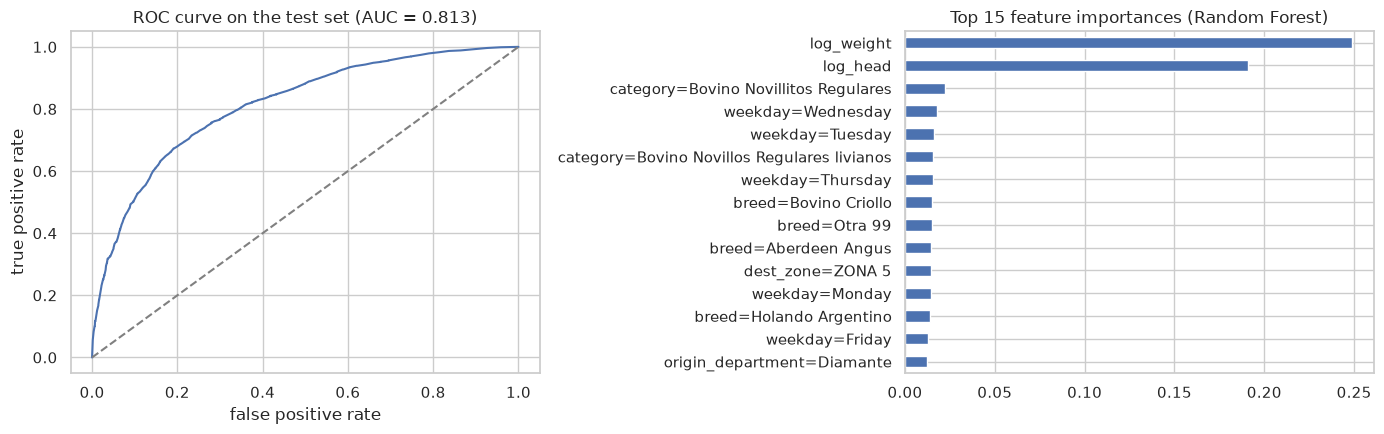

,importance (sum over levels)
log_weight,0.25
origin_department,0.21
log_head,0.19
category,0.10
weekday,0.10
breed,0.09
dest_zone,0.05
origin_province,0.02


In [50]:
importances = pd.Series(final_model.feature_importances_, index=dv_final.get_feature_names_out())
by_variable = (importances.groupby(importances.index.str.split("=").str[0]).sum()
               .sort_values(ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
false_positive_rate, true_positive_rate, _ = roc_curve(y_test, probability)
axes[0].plot(false_positive_rate, true_positive_rate)
axes[0].plot([0, 1], [0, 1], linestyle="--", color="grey")
axes[0].set(title=f"ROC curve on the test set (AUC = {roc_auc_score(y_test, probability):.3f})",
            xlabel="false positive rate", ylabel="true positive rate")
importances.sort_values().tail(15).plot.barh(ax=axes[1])
axes[1].set_title("Top 15 feature importances (Random Forest)")
plt.tight_layout()
plt.savefig(FIGURES / "12_final_model.png", dpi=120)
plt.show()

by_variable.round(3).to_frame("importance (sum over levels)")

In [51]:
# Performance on the Entre Ríos slice of the test set (the use case)
er_mask = (model_df["split"] == "test") & (model_df["origin_province"] == "Entre Rios")
er_dicts, y_er = features_and_target(er_mask)
er_probability = final_model.predict_proba(dv_final.transform(er_dicts))[:, 1]
print(f"Entre Ríos test lots: {er_mask.sum():,}  ROC AUC: {roc_auc_score(y_er, er_probability):.4f}")

Entre Ríos test lots: 2,007  ROC AUC: 0.8343


**Interpretation of the final model**

- **Test AUC 0.813**, against 0.830 in validation: a small drop, so the model generalizes to weeks it never saw.
- **Accuracy 74.6%** against the 55.6% baseline. Precision 0.727: when the model announces a premium, it is right
  about 3 times out of 4. Recall 0.686: it finds 2 of every 3 premium lots.
- On the **Entre Ríos** lots of the test set the AUC is even better: **0.834** — good news for the use case.
- **Feature importance closes question 3.** Weight (0.25), origin department (0.21) and lot size (0.19) dominate;
  the breed contributes 0.09. The breed premiums of section 3.3 are real but secondary: *what* is sold, *how much* of it
  and *from where* matter more than the breed label.
- The weight is a small surprise: alone it showed no correlation with the relative price (section 3.1, Spearman -0.01),
  yet it is the most important feature. Its effect only appears **combined with the category**: what matters is the position
  of the animal within its category's weight range — a multivariate effect invisible in the bivariate analysis.

**Next steps:** `train.py` reproduces this final model outside the notebook; the regression task (`rel_price`) follows
the same recipe; the web service exposes the model.